# Matrix completion via nuclear norm minimization
In this notebook, we study the performance of some algorithms used to complete low-rank matrices where only a small fraction of the entries have been observed.

To visualize performances of these algorithms we use real-world pictures as matrices. First we need to check that real-world pictures are **almost low-rank matrices**. Then we will use an SDP formulation of the nuclear norm minimization procedure. Finally, we will turn to a forward backward splitting algorithm which uses the proximal operator of the nuclear norm.

**package**:

    1. PIL if one wants to use its own images
    2. CVXOPT and CVXPY for solving a SDP

## Load a picture 
Default pictures are available in scipy or any personal picture will do as well.

In [ ]:
from scipy import misc
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

#### scipy pictures

In [ ]:
#Download two images from the scipy database
ascent = misc.ascent()
face = misc.face()

/var/folders/7f/pjr056h92pl6810s6w53r8sm0000gq/T/ipykernel_36087/2230413225.py:2: DeprecationWarning: scipy.misc.ascent has been deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. Dataset methods have moved into the scipy.datasets module. Use scipy.datasets.ascent instead.
  ascent = misc.ascent()
/var/folders/7f/pjr056h92pl6810s6w53r8sm0000gq/T/ipykernel_36087/2230413225.py:3: DeprecationWarning: scipy.misc.face has been deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. Dataset methods have moved into the scipy.datasets module. Use scipy.datasets.face instead.
  face = misc.face()


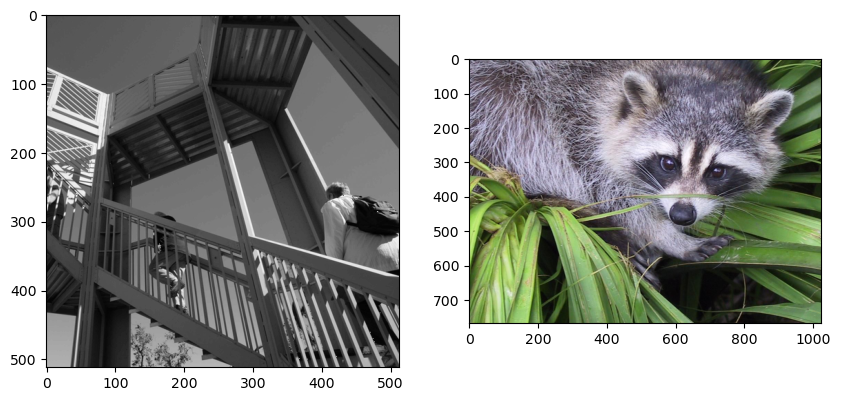

In [ ]:
plt.figure(figsize = (10,10))
plt.subplot(1, 2, 1)
plt.imshow(ascent, cmap=plt.cm.gray)
plt.subplot(1, 2, 2)
plt.imshow(face)

**Option** `cmap=plt.cm.gray(Colormap)`: Maps 2D numerical pixel values ​​to a monochromatic grayscale palette, where the lowest numerical value maps to black and the highest maps to white.

### Decomposition of a colored image

In [ ]:
print(face.shape)
print("colored images are not simple 2d arrays! There are stack of three (and sometimes four) 2d arrays.")

(768, 1024, 3)
colored images are not simple 2d arrays! There are stack of three (and sometimes four) 2d arrays.


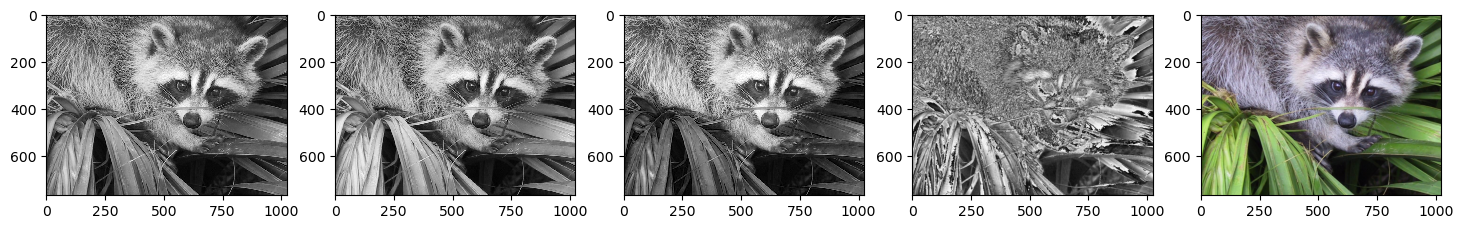

In [ ]:
plt.figure(figsize = (18,10))
plt.subplot(1,5,1)
plt.imshow(face[:,:,0], cmap=plt.cm.gray, interpolation="none")
plt.subplot(1,5,2)
plt.imshow(face[:,:,1], cmap=plt.cm.gray, interpolation="none")
plt.subplot(1,5,3)
plt.imshow(face[:,:,2], cmap=plt.cm.gray, interpolation="none")
plt.subplot(1,5,4)
plt.imshow(face[:,:,0] + face[:,:,1] + face[:,:,2], cmap=plt.cm.gray)
plt.subplot(1,5,5)
plt.imshow(face)

### RGB Is Not an Additive Split of a Single Grayscale Layer

A standard 3-channel image consists of Red, Green, Blue: 

1. RGB channels describe distinct color wavelengths. They do not sum to produce the color image; they must remain separate along the 3rd axis so `plt.imshow` can map them to screen subpixels.

2. Adding color channels together mimics converting to luminance/grayscale, but proper grayscale is a weighted average of RGB (e.g. , $0.299R + 0.587G + 0.114B$), not a raw unweighted sum.

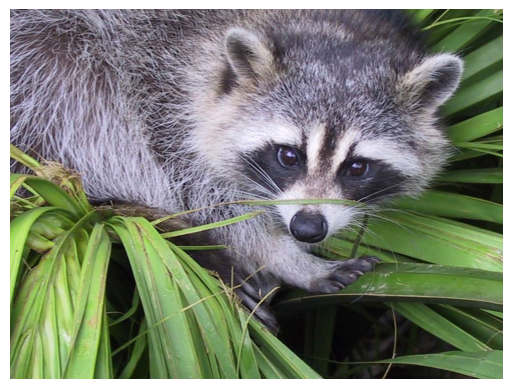

In [ ]:
# Reconstruct by stacking the separate channels back into an RGBA array
reconstructed_rgba = np.stack(
    [face[:, :, 0], face[:, :, 1], face[:, :, 2]],
    axis=-1,
)

plt.imshow(reconstructed_rgba)
plt.axis("off")
plt.show()

#### Personnal pictures
Personnal pictures can be loaded via the library PIL. Loaded colored images has a PIL type which is not a classical matrix (it is a list of triples). So for our study we will only consider one slice of this list.

In [ ]:
essec = Image.open("essec.png")

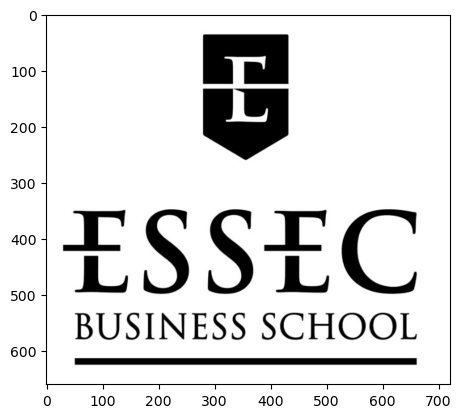

In [ ]:
plt.imshow(essec)

In [ ]:
essec_np = np.array(essec)
essec_np.shape

(660, 720, 4)

In [ ]:
#Let us conisder only the first array from both images and work on it for the study of matrix completion
essec = essec_np[:,:, 0]
face = face[:,:, 0]

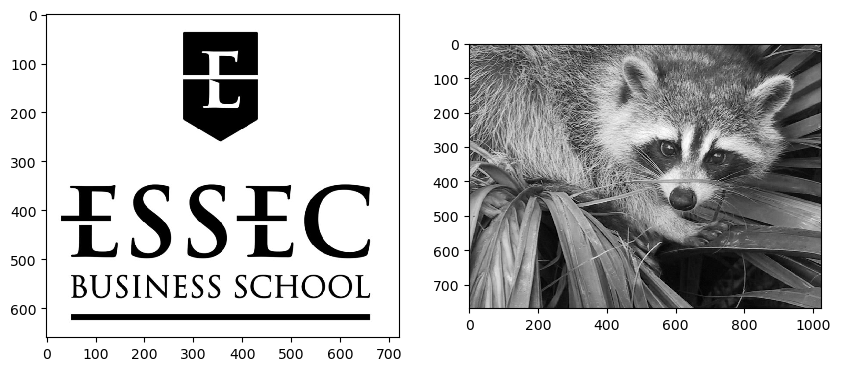

In [ ]:
plt.figure(figsize = (10,10))
plt.subplot(1,2,1)
plt.imshow(essec, cmap=plt.cm.gray, interpolation="none")
plt.subplot(1,2,2)
plt.imshow(face, cmap=plt.cm.gray, interpolation="none")

**Exercise:** Download your own image

## Pictures as np.array
Pictures loaded in python can now be seen as np.array

In [ ]:
print(type(essec), type(face))
print(essec.shape, face.shape)

<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(660, 720) (768, 1024)


In [ ]:
face[0:10, 0:10]

array([[121, 138, 153, 155, 155, 158, 159, 156, 147, 137],
       [ 89, 110, 130, 137, 141, 148, 152, 151, 164, 154],
       [ 73,  94, 115, 123, 127, 131, 132, 129, 139, 135],
       [ 81,  97, 113, 120, 125, 126, 120, 111, 101, 101],
       [103, 113, 123, 132, 142, 147, 140, 127, 109, 101],
       [124, 128, 131, 137, 150, 163, 163, 155, 136, 119],
       [109, 110, 108, 108, 122, 144, 159, 163, 155, 143],
       [ 68,  70,  67,  66,  81, 112, 142, 157, 170, 170],
       [102,  94,  85,  80,  74,  80, 106, 136, 166, 179],
       [123, 116, 108,  97,  83,  75,  82,  95, 135, 158]], dtype=uint8)

In [ ]:
essec[0:10, 0:10]

array([[255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255]], dtype=uint8)

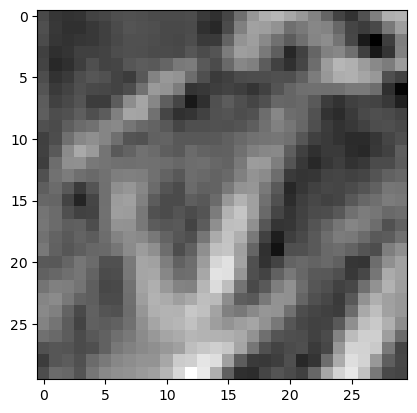

In [ ]:
plt.imshow(face[100:130, 100:130], cmap=plt.cm.gray, interpolation="none")

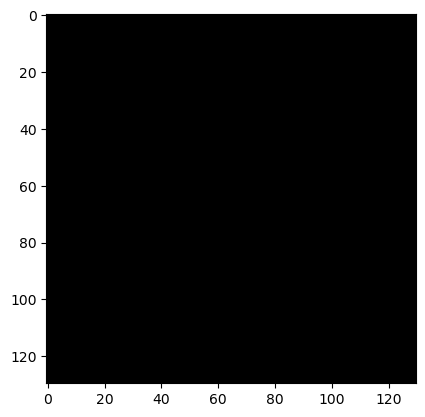

In [ ]:
plt.imshow(essec[:130, :130], cmap=plt.cm.gray, interpolation="none")

**Note:** In the slice `essec[:130, :130]` all values are 255. Hence, min=max=255. By default, when `plt.imshow` renders a 2D array, it maps the minimum value present to the darkest color and the maximum value to the brightest. We can use the option `vmin=0, vmax=255` to set the scale by hand and get the white square from  `essec[:130, :130]` as expected.

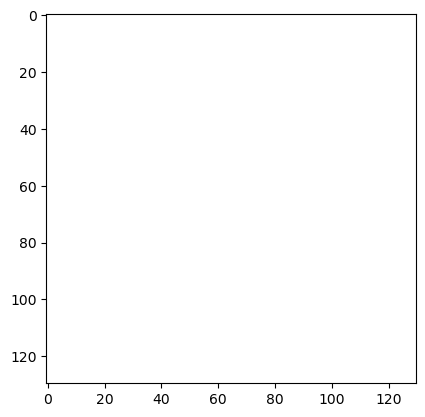

In [ ]:
plt.imshow(essec[:130, :130], cmap=plt.cm.gray, interpolation="none", vmin=0, vmax=255)

## Real-world images are "almost" low-rank matrices!
**Recap:** Any matrix $A\in\mathbb{R}^{u\times v}$ has a singular value decomposition (SVD): there exists $U\in O(u)$ and $V\in O(v)$ two orthogonal matrices such that
$$
A=U S V = \sum_{i=1}^{\min(u, v)} \sigma_i u_i v_i^\top
$$
where $S= {\rm diag}(\sigma_A)\in\R^{u\times v}$ and $\sigma_A=(\sigma_1,\ldots,\sigma_{u\wedge v})$ is the spectrum of $A$, $(u_i)$ are the column vectors of $U$ and $(v_i)$ are the row vectors or $V$. The **rank** of $A$ is the size of the support of the spectrum of $A$ (i.e. the $\ell_0$-norm of $\sigma_A$). 

In **Python**, one can get this decomposition via numpy:

> U, s, V = numpy.linalg.svd(A)

Note that $s$  is the vector of all singular values ordered in a decreasing way; to get the diagonal matrix $S$ from $s$ one can use **np.diag(s)**. In this case,  **np.dot(U, np.dot(S, V))}** is close to $A$.

> S = np.diag(s)

> np.dot(U, np.dot(S, V))

**Note:** np.diag(s) return a square matrix whereas we need a rectangular $u\times v$ matrix. So to make the exposition simple, we will work only with square matrix (i.e. $u=v$).

In [ ]:
from numpy.linalg import svd

In [ ]:
face = face[0:768, 0:768] # to get a square matrix
U, s, V = svd(face)

In [ ]:
S = np.diag(s)
FACE = np.dot(U, np.dot(S, V))
print(np.allclose(face, FACE))
print(np.linalg.norm(FACE-face, 2))

True
2.92270853274239e-10


(-5.0, 55.0)

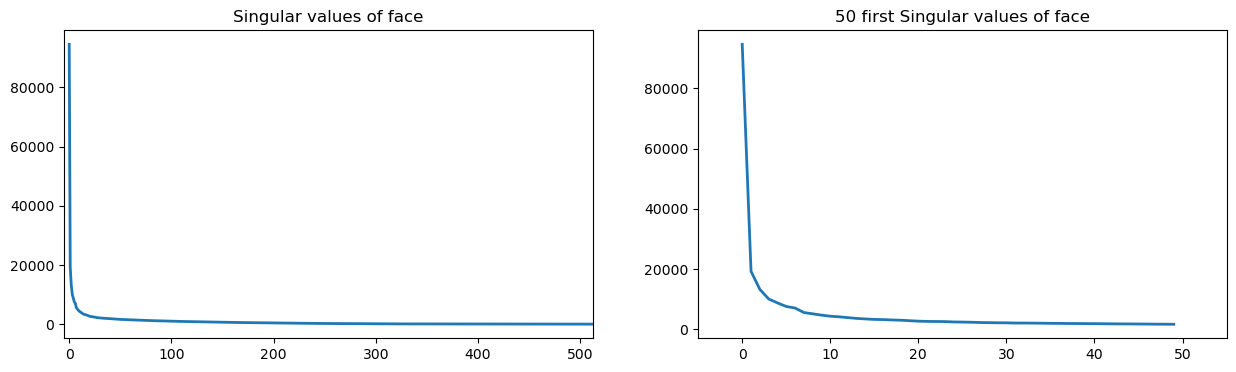

In [ ]:
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
plt.plot(s, lw=2)
plt.title("Singular values of face")
plt.xlim([-5, 512])
plt.subplot(1,2,2)
plt.plot(s[0:50], lw=2)
plt.title("50 first Singular values of face")
plt.xlim([-5, 55])

(-5, 55)

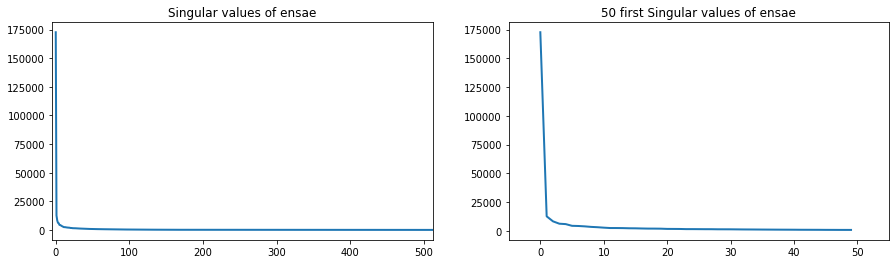

In [ ]:
U, s, V = svd(essec)
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
plt.plot(s,  lw=2)
plt.title("Singular values of essec")
plt.xlim([-5, 512])
plt.subplot(1,2,2)
plt.plot(s[0:50], lw=2)
plt.title("50 first Singular values of essec")
plt.xlim([-5, 55])

**Conclusion: images are amazingly "almost" low rank!**

Let us see if one truncates the SVD of an image (by setting many small singular values to zero) one can recover the original picture.

## Images with truncated svd
Truncated SVD follows from the *svds* scipy method [here](http://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.svds.html) or via sklearn [here](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html). Below we just use the numpy *svd* method and keep only the first singular values (i.e. the largest one), setting the other to zero.

In [ ]:
def truncated_svd(image = face, rank = 50):
    """Return the SVD with truncated spectrum at a given rank"""
    #TODO
    return U, s, V  

In [ ]:
image, rank = face, 50
U, sr, V = truncated_svd(image, rank)
S_r = np.diag(sr)
face_r = np.dot(U, np.dot(S_r, V))

Text(0.5, 1.0, 'Singular values of face')

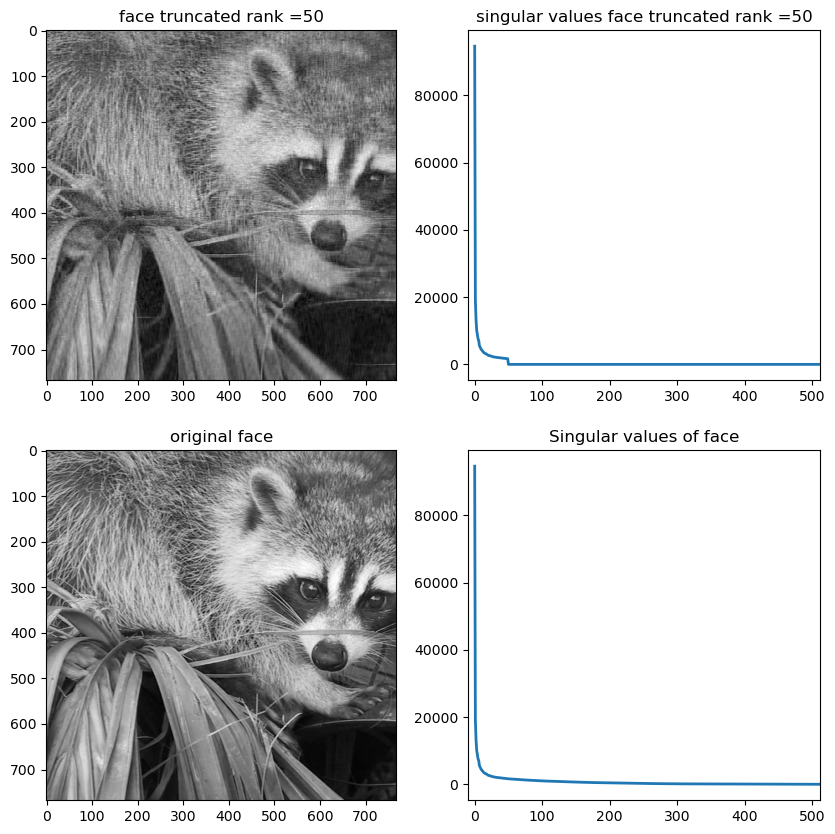

In [ ]:
plt.figure(figsize = (10, 10))
plt.subplot(2,2,1)
plt.imshow(face_r, cmap=plt.cm.gray, interpolation="none")
titre = 'face truncated rank ={}'.format(rank)
plt.title(titre)
plt.subplot(2,2,2)
plt.plot(sr, lw = 2)
plt.xlim([-10, 512])
titre = 'singular values face truncated rank ={}'.format(rank)
plt.title(titre)
plt.subplot(2, 2, 3)
plt.imshow(face, cmap=plt.cm.gray)
plt.title("original face")
plt.subplot(2,2,4)
plt.plot(s, lw=2)
plt.xlim([-10, 512])
plt.title("Singular values of face")

**Exercise:** Plot your own image, its spectrum and do the same for its truncated one.

## Construction of a dataset using a mask
We remove randomly some entries from the matrix associated to an image using Bernoulli variables; this is what we call a **mask**. We can formalize it as a function

$$
P_\Omega : \left\{
\begin{array}{ccc}
\mathbb{R}^{u\times v} & \to & \mathbb{R}^{u\times v}\\
A & \to & P_\Omega(A)
\end{array}
\right. \text{ where } (P_\Omega(A))_{ij} = \left\{
\begin{array}{cc}
A_{ij} & \text{ if } (i,j)\in\Omega\\
0 & \text{ otherwise}
\end{array}
\right.
$$
and $\Omega\subset\{1,\ldots,u\}\times \{1,\ldots,v\}$ is the set of indices of the observed entries. 

In the following, this set is constructed randomly using **selectors** (i.e. Bernoulli variables): every entry is selected with some probability called *proportion* below. We look at $P_\Omega(A)$ as a dataset of the form **{(user, item, grade)}** where $(user, item)\in\Omega$ and *grade* is the value of the pixel at the coordinate (user, item) of the image. This is the classical shape of datasets for the construction of *recommandation systems*.


In [ ]:
def mask(u, v, proportion = 0.2):
    mat_mask = np.random.binomial(1, proportion, size =  (u, v))
    print(f"We observe {100 * mat_mask.mean():.2f} per cent of the entries of a {u}*{v} matrix")
    return mat_mask

In [ ]:
image = face
proportion = 0.2
u, v = image.shape
mat_mask = mask(u, v, proportion)
image_masked = np.multiply(mat_mask, image)

We observe 20.00 per cent of the entries of a 768*768 matrix


Text(0.5, 1.0, 'Observed entries; black = unobserved')

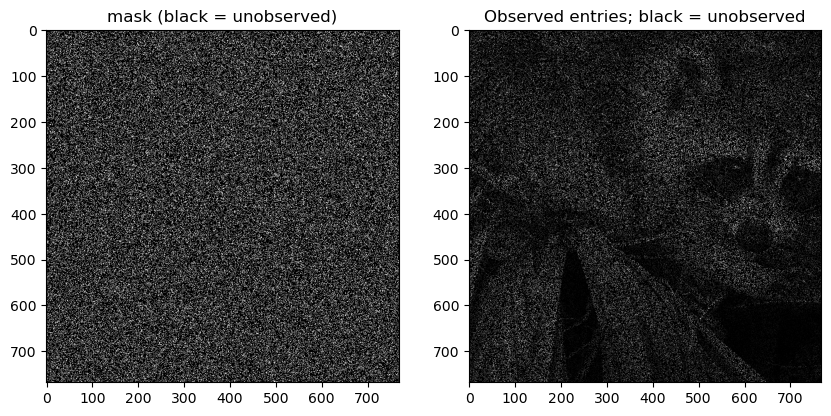

In [ ]:
plt.figure(figsize = (10,10))
plt.subplot(1, 2, 1)
plt.imshow(mat_mask, cmap=plt.cm.gray); plt.title("mask (black = unobserved)")
plt.subplot(1, 2, 2)
plt.imshow(image_masked, cmap=plt.cm.gray); plt.title("Observed entries; black = unobserved")

In [ ]:
rank = 30
image = face
U, sr, V = truncated_svd(image, rank)
S_r = np.diag(sr)
image_r = np.dot(U, np.dot(S_r, V))
proportion = 0.2
u, v = image_r.shape
mat_mask = mask(u, v, proportion)

We observe 20.06 per cent of the entries of a 768*768 matrix


**Conclusion:** now that we have observed some entries of a low-rank matrix, one can tries to complete it via some "matrix completion algorithms". The nuclear norm will play a central role in the following procedures.

# Matrice completion via nuclear norm minimization

The convex relaxation procedure derived from rank minimization is the nuclear norm minimization procedure:


$$
\hat A \in \argmin_{A\in \R^{u\times v}}\big(\|A\|_{S_1} : \mathcal{A}(A) = y\big).\tag{NM}
$$
where $\mathcal{A}(A) = (<A, X_i>)_{i=1}^m$,  $y=\mathcal{A}(A^*)$, $A^*$ is the low-rank matrix that we want to reconstruct and $\|\cdot\|_{S_1}$ is the nuclear norm (that is the sum of singular values).

It is possible to recast (NM) as a SDP problem: 

$$
\left(
\begin{array}{c}
\hat X\\
\hat Y\\
\hat Z
\end{array}
\right)\in\argmin_{X\in\mathbb{R}^{u\times v}, Y\in\mathcal{S}^u, Z\in\mathcal{S}^v} {\rm Tr}(Y) + {\rm Tr}(Z) \text{ tel que } 
\begin{array}{l}
\mathcal{A}(X) = y\\
\left[
\begin{array}{cc}
Y & X\\
X^\top & Z
\end{array}
\right]\succeq 0
\end{array}\tag{SDP}
$$

**Theorem**

The two problems (NM) and (SDP) are equivalent :

1)  if $\hat A$ is a  solution to (NM) then  $(\hat A, \hat Y, \hat Z)^\top$ is a solution to (SDP) for some $\hat Y$ et $\hat Z$,

2) if $(\hat X, \hat Y, \hat Z)^\top$ is solution to (SDP) then $\hat X$ is solution to (NM).


#### Thanks to cvxpy we can directly ask to solve the nuclear norm minimlization problem (NM) directly without having to write it in its SDP formulation. This is what we are doing below.

In [ ]:
# Takes 1m40s
!pip install cvxpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 17.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached cffi-2.0.0-cp39-cp39-macosx_10_13_x86_64.whl.metadata (2.6 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached pycparser-2.23-py3-none-any.whl.metadata (993 bytes)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 9.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 54.4 MB/s  0:00:00
Using cached cffi-2.0.0-cp39-cp39-macosx_10_13_x86_64.whl (184 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached pycparser-2.23-py3-none-any.whl (118 kB)
  Created wheel for scs: filename=scs-3.3.1-cp39-cp39-macosx_10_16_x86_64.whl size=258432 sha256=875ca0cf657ff71ad005bf7dcd5cfe0b776a0b972a0ef831

In [ ]:
from cvxpy import *
print(installed_solvers())

['CLARABEL', 'CVXOPT', 'GLPK', 'GLPK_MI', 'OSQP', 'SCIPY', 'SCS']


**Note**: Only the solvers 'SCS' or 'CVXOPT' can solve SDP problems (cf. [cvxpy 'Choosing a solver chapter](http://www.cvxpy.org/en/latest/tutorial/advanced/)). For the time being, only SCS works on my machine for this problem. Using 'CVXOPT' always leads to a *dead kernel* after a minute of computation. The reason is that CVXOPT uses an Interior-Point Method that is a Second-Order Newton algorithm whereas SCS uses ADMM, a First-Order algorithm.

In the following cell, we solve the SDP formulation (SDP) of the nuclear norm minization (NM) problem via CVXPY. To that end, we only have to define the objective function (i.e. 'obj') and the constraints (i.e. 'constraints') 

In [ ]:
def nuclear_norm_mini(mat_mask, image):
    u, v = image.shape
    A = Variable((u, v))
    obj = #TODO visit cvxopt webpage and find the right objective function
    constraints = #TODO visit cvxopt webpage and find the right constraint
    prob = Problem(obj, constraints)
    prob.solve(solver=SCS)
    if prob.status != 'optimal':
        print('CVXPY failed to reach optimal value')
    return A.value

In [ ]:
rank = 30
size = 180
image = face[0:size, 0:size]
U, sr, V = truncated_svd(image, rank)
S_r = np.diag(sr)
image_r = np.dot(U, np.dot(S_r, V))
proportion = 0.5
u, v = image_r.shape
mat_mask = mask(u, v, proportion)

We observe 49.89 per cent of the entries of a 180*180 matrix


In [ ]:
A = nuclear_norm_mini(mat_mask, image_r)

6.645439863204956 seconds


Text(0.5, 1.0, 'Image reconstructed via nuclear norm minimization')

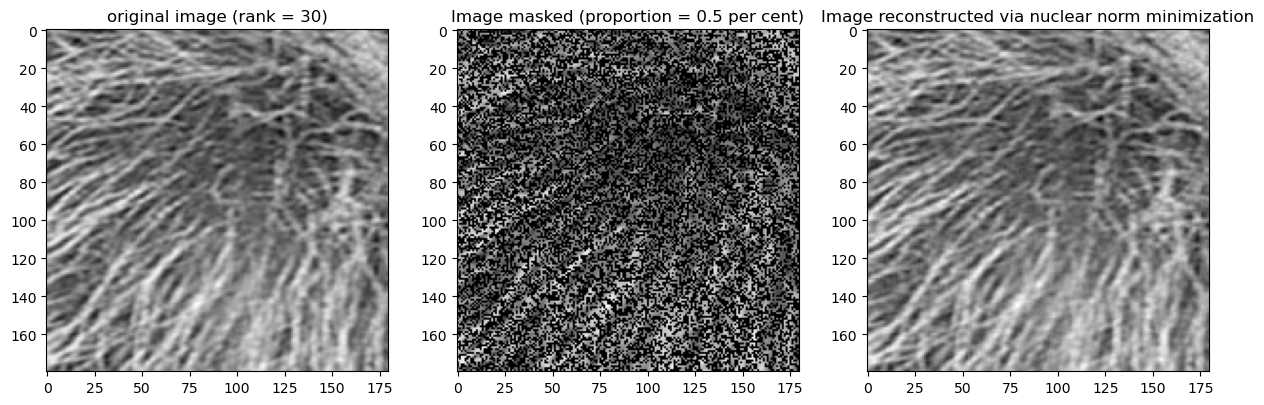

In [ ]:
plt.figure(figsize = (15, 10))
plt.subplot(1,3,1)
plt.imshow(image_r, cmap=plt.cm.gray)
plt.title("original image (rank = {})".format(rank))
plt.subplot(1,3,2)
plt.imshow(np.multiply(mat_mask, image_r), cmap=plt.cm.gray)
plt.title("Image masked (proportion = {} per cent)".format(proportion))
plt.subplot(1,3,3)
plt.imshow(A, cmap=plt.cm.gray)
plt.title("Image reconstructed via nuclear norm minimization")

In [ ]:
def recons_plot(image, size=100, rank=30, proportion=0.2):
    U, sr, V = truncated_svd(image[0:size, 0:size], rank)
    S_r = np.diag(sr)
    image_r = np.dot(U, np.dot(S_r, V))
    u, v = image_r.shape
    mat_mask = mask(u, v, proportion)
    A = nuclear_norm_mini(mat_mask, image_r)
    plt.figure(figsize = (15, 10))
    plt.subplot(1,3,1)
    plt.imshow(image_r, cmap=plt.cm.gray)
    plt.title(f"original image (rank = {rank})")
    plt.subplot(1,3,2)
    plt.imshow(np.multiply(mat_mask, image_r), cmap=plt.cm.gray)
    plt.title(f"Image masked (proportion = {proportion} per cent)")
    plt.subplot(1,3,3)
    plt.imshow(A, cmap=plt.cm.gray)
    plt.title("Image reconstructed via nuclear norm minimization")    

We observe 41.16 per cent of the entries of a 50*50 matrix


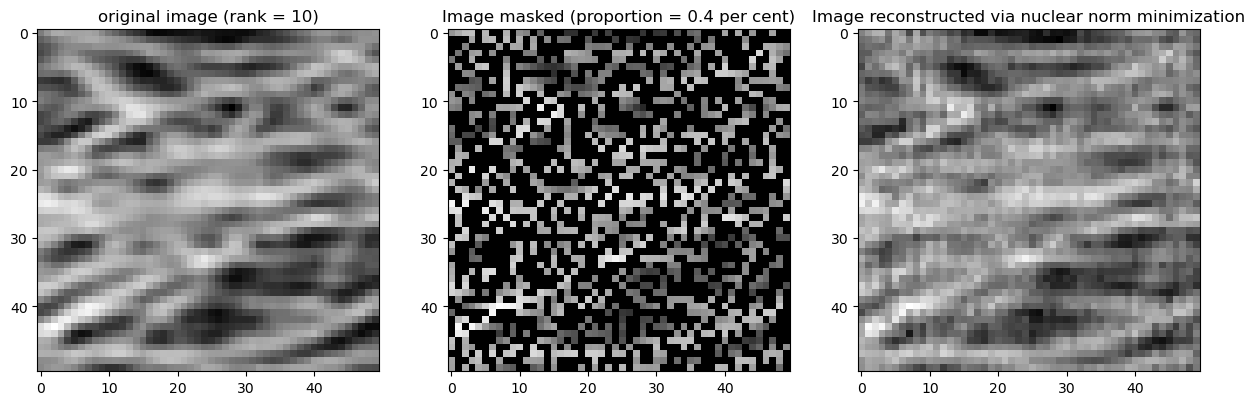

In [ ]:
recons_plot(face, size=50, rank=10, proportion=0.4)

We observe 39.72 per cent of the entries of a 100*100 matrix
We observe 39.56 per cent of the entries of a 100*100 matrix


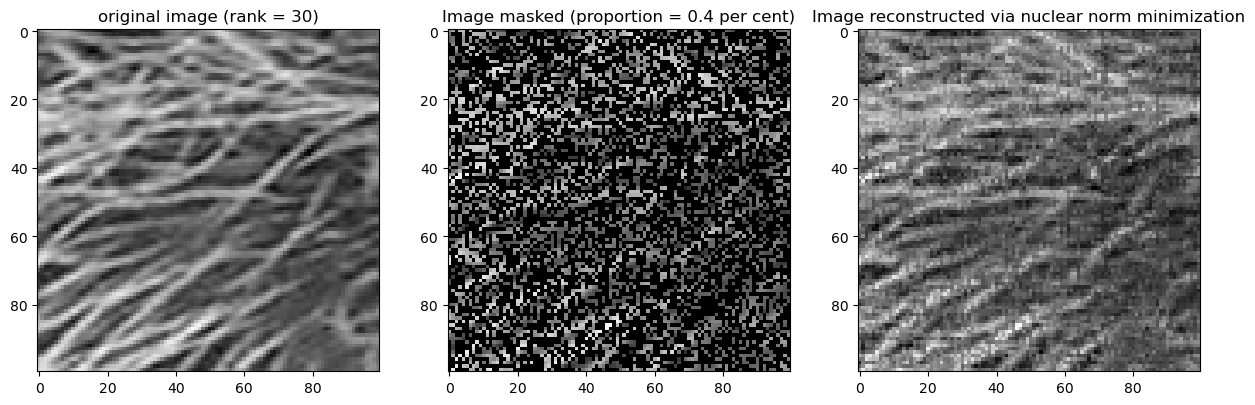

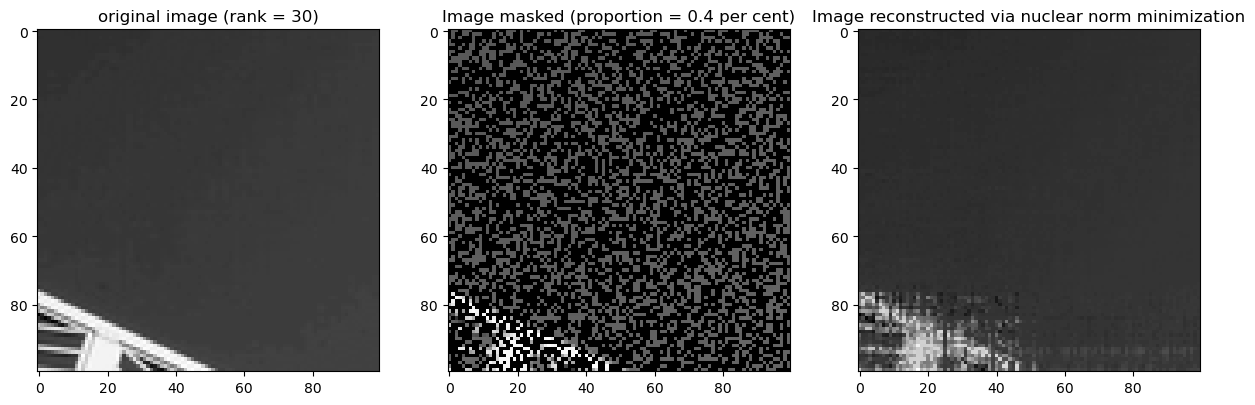

In [ ]:
images = [face, ascent]
for image in images:
    recons_plot(image, size=100, rank=30, proportion=0.4)

We observe 39.88 per cent of the entries of a 300*300 matrix


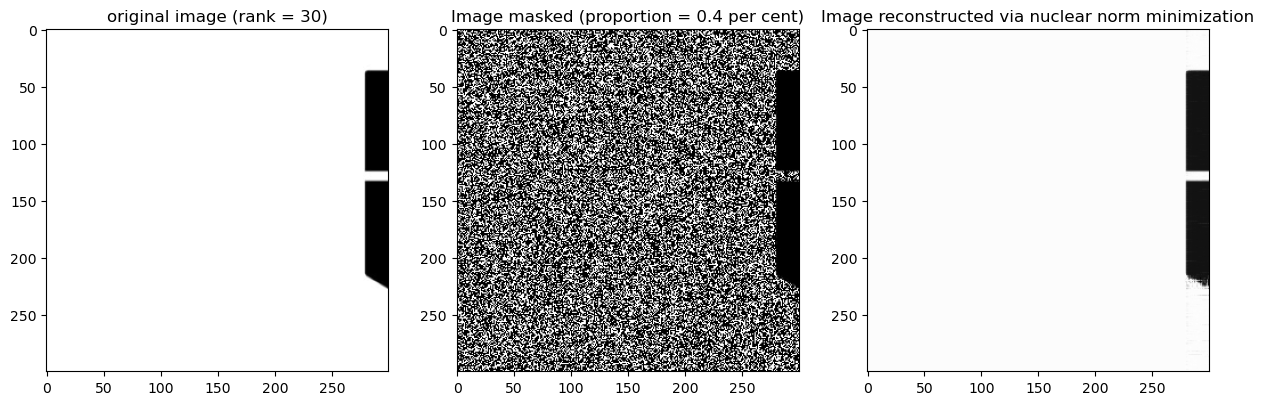

In [ ]:
#It takes 57s
recons_plot(essec, size=300, rank=30, proportion=0.4)

**Conclusion**: 

1) Nuclear norm minimization via cvxpy works well up to matrices of size $200\times200$. 

2) It is harder to reconstruct matrices that are sparse and low rank. This last observation is known in theory since matrice completion works well only when the singular vectors (of the matrix to be reconstructed) are incoherent with the canonical basis. This is not the case of sparse + low-rank matrices. 

**Exercise:** 

Consider your own image, take a patch of it (150*150) and do SVD truncation, mask it using a random mask and reconstruct the original image via nuclear norm minimization.

## Matrix Completion via Proximal gradient descent
Given the data $P_\Omega(A^*)$, one may try to recover $A^*$ via the least-squares regularization procedure:

$$
\hat A \in\argmin_{A\in\mathbb{R}^{u\times v}} \frac{1}{2}\|P_\Omega(A^*) - P_\Omega(A)\|_{S_2}^2 + \lambda \|A\|_{S_1}
$$where $\lambda$ is a regularization parameter.

A way to implement this procedure is to perform a proximal gradient descent: 

$$
A^{k+1} = {\rm prox}_{\gamma_k \lambda\|\cdot\|_{S_1}}\big(A^k - \gamma_k \nabla F(A^k)\big) \text{ where } F(A) = \frac{1}{2}\|P_\Omega(A^*) - P_\Omega(A)\|_{S_2}^2.
$$
One can see that $\nabla F(A) =  (P_\Omega(A)-P_\Omega(A^*))$ and that the proximal operator of $\gamma_k \lambda\|\cdot\|_{S_1}$ is the **spectral soft thresholding operator** $S_\mu$ -- for $\mu = \gamma_k\lambda$:

$$
{\rm prox}_{\mu\|\cdot\|_{S_1}}(A) = S_\mu(A) = US_{\mu} V 
$$
where a SVD of $A$ is $A = USV$ and $S_\mu = {\rm diag}((\sigma_1-\mu)_+, (\sigma_2-\mu)_+, \cdots)$ is the $u\times v$ diagonal matrix of the soft threshold of the spectrum of $A$.

#### Spectral soft-thresholding operator

In [ ]:
def spectral_soft_thresh(A, mu):
    """Return the soft-thresholding version of A with shift mu"""
    U, s, V = #TODO
    s_mu = #TODO
    return np.dot(U, np.dot(np.diag(s_mu), V))

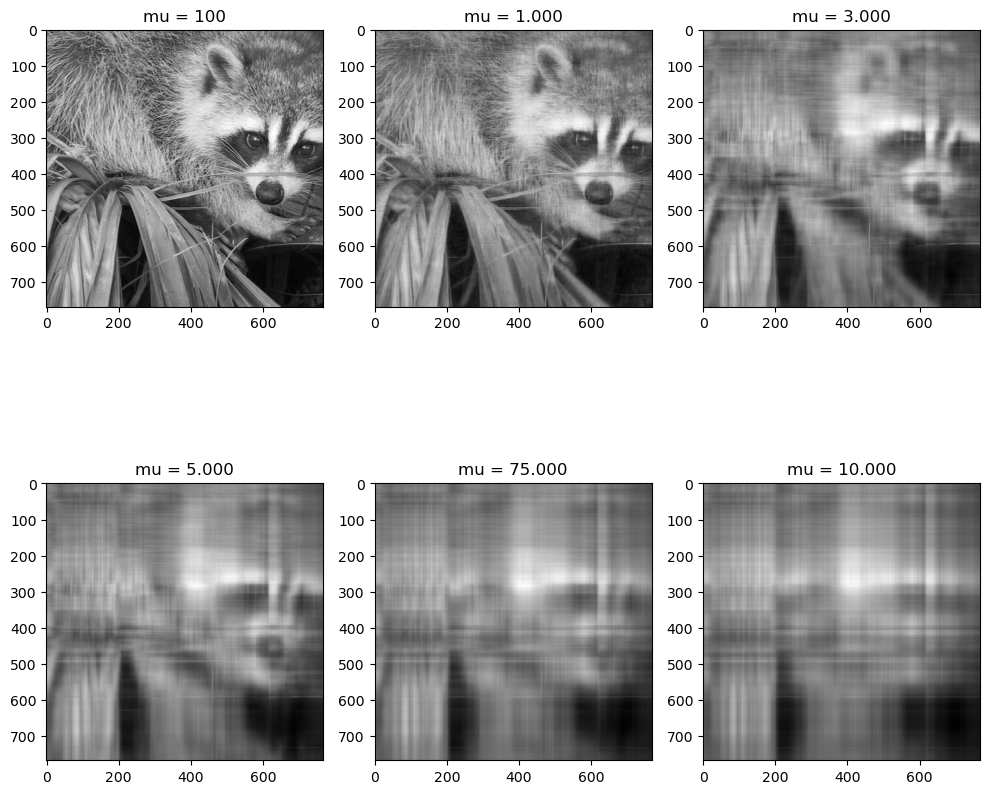

In [ ]:
#Soft-thresholding with shift parameter mu on some image for various choice of mu
plt.figure(figsize=(10, 10))
plt.subplot(2, 3, 1)
image = spectral_soft_thresh(face, 100)
plt.imshow(image, cmap = plt.cm.gray)
plt.title("mu = 100")
plt.subplot(2, 3, 2)
image = spectral_soft_thresh(face, 1000)
plt.imshow(image, cmap = plt.cm.gray)
plt.title("mu = 1.000")
plt.subplot(2, 3, 3)
image = spectral_soft_thresh(face, 3000)
plt.imshow(image, cmap = plt.cm.gray)
plt.title("mu = 3.000")
plt.subplot(2, 3, 4)
image = spectral_soft_thresh(face, 5000)
plt.imshow(image, cmap = plt.cm.gray)
plt.title("mu = 5.000")
plt.subplot(2, 3, 5)
image = spectral_soft_thresh(face, 7500)
plt.imshow(image, cmap = plt.cm.gray)
plt.title("mu = 75.000")
plt.subplot(2, 3, 6)
image = spectral_soft_thresh(face, 10000)
plt.imshow(image, cmap = plt.cm.gray)
plt.title("mu = 10.000")
plt.tight_layout()

**We define the proximal gradient descent** for $\gamma_k=1$ that is:

$$
A^{k+1} = S_\lambda(P_{\Omega^c}(A^k) + P_\Omega(A^*))
$$

In [ ]:
def prox_grad_descent(image, mat_mask, mu, n_iter=100, verbose = False):
    image_masked = np.multiply(image, mat_mask)
    list_errors = []
    A = np.zeros(image_masked.shape)
    for i in range(n_iter + 1):
        A = spectral_soft_thresh(A * (1 - mat_mask) + image_masked, mu)
        err = np.linalg.norm(A - image, 2) / np.linalg.norm(image, 2)
        list_errors.append(err)
        if i % 20 == 0 and verbose == True:
            print("iteration = {}; error = {}".format(i, err))
            plt.figure
            plt.imshow(A, cmap = plt.cm.gray)
            plt.show()
    return A, list_errors

We observe 19.96 per cent of the entries of a 768*768 matrix
iteration = 0; error = 0.8028180889438193


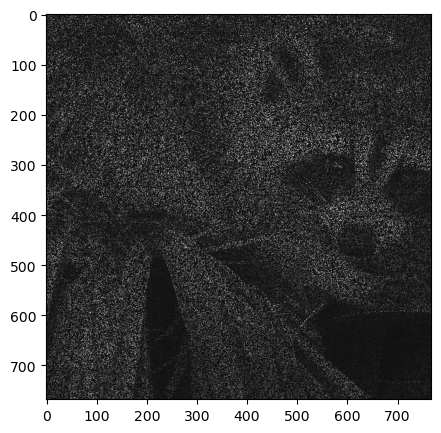

iteration = 20; error = 0.5273564766597562


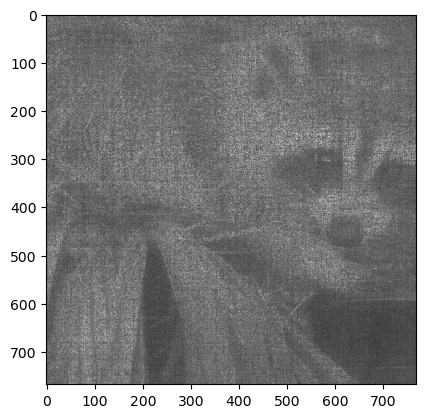

iteration = 40; error = 0.32454862523696204


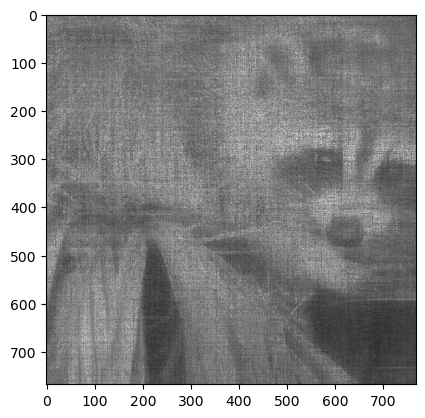

iteration = 60; error = 0.181373786648728


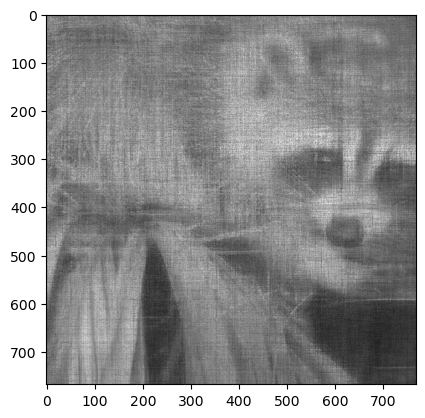

iteration = 80; error = 0.09645497753287419


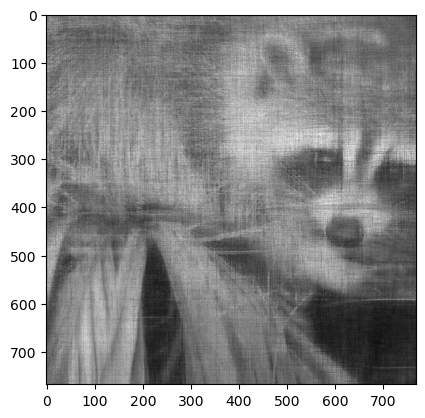

iteration = 100; error = 0.05686257223918512


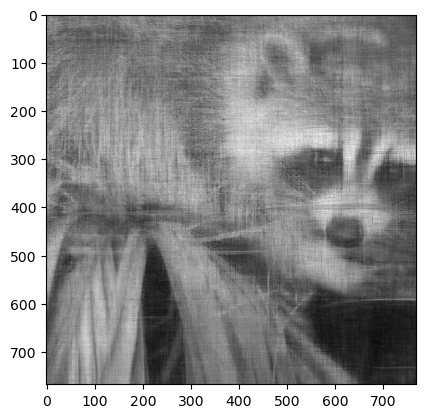

In [ ]:
#It takes 2 mins 10s
mu = 200
size = 100
proportion = 0.2

image = face#[0:size, 0:size]
u, v = image.shape
mat_mask = mask(u, v, proportion)

plt.figure(figsize=(5, 5))
image_reconstructed, list_errors = prox_grad_descent(image, mat_mask, mu, verbose=True)

**Exercise:**

Visualize the evolution of the proximal gradient method on your own image.

### Evolution of relative error along the descent

Text(0.5, 1.0, 'Evolution of the relative error along the projected descent')

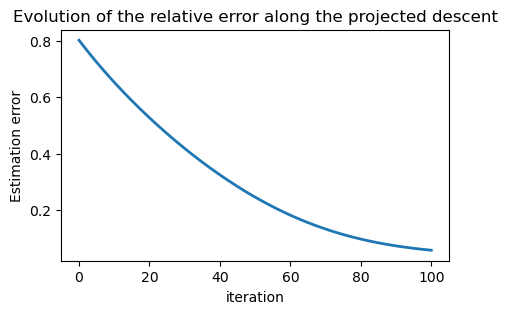

In [ ]:
plt.figure(figsize=(5, 3))
plt.plot(list_errors, linewidth=2)
plt.xlabel("iteration")
plt.ylabel("Estimation error")
plt.title("Evolution of the relative error along the projected descent")

In [ ]:
rank = np.linalg.matrix_rank(image_reconstructed)
U, sr, V = truncated_svd(image, rank)
S_r = np.diag(sr)
image_r = np.dot(U, np.dot(S_r, V))

Text(0.5, 1.0, 'Data')

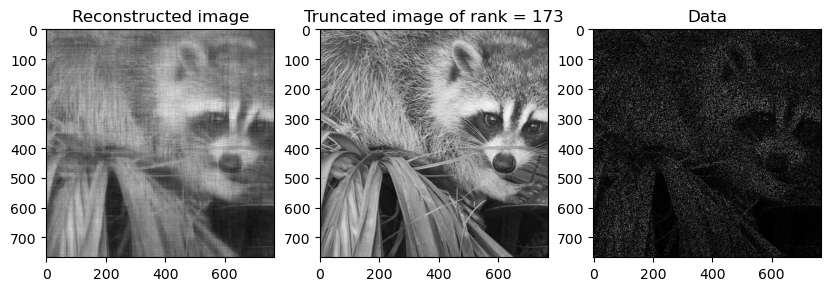

In [ ]:
plt.figure(figsize = (10, 10))
#plt.rcParams['figure.figsize'] = 6., 4.
plt.subplot(1, 3, 1)
plt.imshow(image_reconstructed, cmap = plt.cm.gray)
plt.title("Reconstructed image")
plt.subplot(1, 3, 2)
plt.imshow(image_r, cmap = plt.cm.gray)
plt.title("Truncated image of rank = {}".format(rank))
plt.subplot(1, 3, 3)
plt.imshow(np.multiply(image, mat_mask), cmap = plt.cm.gray)
plt.title("Data")

**Exercise:**

Visualize your original image with spectral truncation at a given rank, its masked version and the reconstructed one via proximal gradient descent.